# CareerMind — Agent 1: Job Classification
**Course:** 24CSE0316 — Artificial Intelligence & Machine Learning

**Workflow:** Load data → Validate → EDA → Text and feature engineering → Train/test split → Train syllabus classifiers → Compare metrics → Select best model → Save model and results.

**Target:** `job_category`

This notebook uses the custom synthetic academic dataset. Report metrics as performance on this dataset, not as verified real-world job-market accuracy.

## 1. Setup and Load Dataset

In [59]:

# ============================================================
# CAREERMIND - COMMON SETUP FOR ALL THREE AGENTS
# ============================================================

import os
import re
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings("ignore")

# Original shared CareerMind folder
BASE = "/content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind"

# Data directories
DATA_DIR = os.path.join(BASE, "Data")
RAW_DIR = os.path.join(DATA_DIR, "Raw")
CLEAN_DIR = os.path.join(DATA_DIR, "Cleaned")
PROCESSED_DIR = os.path.join(DATA_DIR, "Processed")

# Model and result directories
MODEL_DIR = os.path.join(BASE, "Models")
RESULTS_DIR = os.path.join(BASE, "Results")

# Agent-specific directories
CLASSIFIER_DIR = os.path.join(MODEL_DIR, "Classifier")
PREDICTOR_DIR = os.path.join(MODEL_DIR, "Predictor")
GROUPING_DIR = os.path.join(MODEL_DIR, "Grouping")

# Create output directories
for folder in [
    PROCESSED_DIR, RESULTS_DIR,
    CLASSIFIER_DIR, PREDICTOR_DIR, GROUPING_DIR
]:
    os.makedirs(folder, exist_ok=True)

# Load cleaned V2 dataset
DATA_PATH = os.path.join(
    CLEAN_DIR,
    "careermind_master_dataset_v2.csv"
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("=" * 55)
print("CAREERMIND - DATASET LOADED")
print("=" * 55)
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Columns:", df.columns.tolist())

display(df.head(3))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CAREERMIND - DATASET LOADED
Shape: (6000, 15)
Missing values: 0
Duplicate rows: 0
Columns: ['job_id', 'job_title', 'job_description', 'skills', 'experience_min_years', 'experience_max_years', 'experience_midpoint_years', 'experience_level', 'location', 'job_category', 'minimum_annual_salary_inr', 'maximum_annual_salary_inr', 'average_annual_salary_inr', 'currency', 'salary_period']


,job_id,job_title,job_description,skills,experience_min_years,experience_max_years,experience_midpoint_years,experience_level,location,job_category,minimum_annual_salary_inr,maximum_annual_salary_inr,average_annual_salary_inr,currency,salary_period
0,CM000760,Engineer,Collaborates with business and technical teams...,"NumPy, Project Coordination",7,11,9.0,Senior,Hyderabad,Data Science & AI,2420000,2920000,2670000,INR,Annual
1,CM002306,Operations Associate,"Reviews workflows, prepares status updates, su...","Linux, Firewalls, Python, Data Analysis, Tally",4,7,5.5,Mid Level,Gurugram,Cybersecurity,900000,1180000,1040000,INR,Annual
2,CM002285,Security Analyst,"Collects and reviews information, identifies i...","Incident Response, SIEM, Python, Communication...",4,7,5.5,Mid Level,Jaipur,Cybersecurity,970000,1250000,1110000,INR,Annual


In [60]:
import os

BASE = "/content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind"

for folder in ["Raw", "Cleaned", "Processed"]:
    path = os.path.join(BASE, "Data", folder)

    print(f"\n--- {folder} ---")

    for file in os.listdir(path):
        print(file)


--- Raw ---
careermind_master_dataset_v2.csv

--- Cleaned ---
career_mind_full_cleaned.csv
careermind_master_dataset_v2.csv

--- Processed ---
regression_api_data.csv
classification_processed.csv


## 2. Dataset Validation

In [61]:
# Dataset quality checks
print("Rows, columns:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate full rows:", df.duplicated().sum())
print("Duplicate job IDs:", df["job_id"].duplicated().sum())
print("\nData types:\n", df.dtypes)
assert df["job_id"].is_unique, "Duplicate job_id values found."
assert df.isna().sum().sum() == 0, "Missing values found. Inspect before training."
assert set(df["currency"].astype(str).str.upper().unique()) == {"INR"}, "Unexpected currency found."
assert set(df["salary_period"].astype(str).str.lower().unique()) == {"annual"}, "Salary period is not consistently annual."
assert (df["minimum_annual_salary_inr"] <= df["maximum_annual_salary_inr"]).all()
assert np.allclose(
    df["average_annual_salary_inr"],
    (df["minimum_annual_salary_inr"] + df["maximum_annual_salary_inr"]) / 2
), "Average salary does not match min/max midpoint."
print("\nAll initial dataset checks passed.")

Rows, columns: (6000, 15)

Missing values:
 job_id                       0
job_title                    0
job_description              0
skills                       0
experience_min_years         0
experience_max_years         0
experience_midpoint_years    0
experience_level             0
location                     0
job_category                 0
minimum_annual_salary_inr    0
maximum_annual_salary_inr    0
average_annual_salary_inr    0
currency                     0
salary_period                0
dtype: int64

Duplicate full rows: 0
Duplicate job IDs: 0

Data types:
 job_id                        object
job_title                     object
job_description               object
skills                        object
experience_min_years           int64
experience_max_years           int64
experience_midpoint_years    float64
experience_level              object
location                      object
job_category                  object
minimum_annual_salary_inr      int64
maximum_annu

## 3. Exploratory Data Analysis

Dataset shape: (6000, 15)
Number of categories: 12


,job_count
job_category,
Data Science & AI,500
Cybersecurity,500
Marketing,500
Data Analytics,500
Sales,500
QA & Testing,500
UI/UX & Design,500
Cloud & DevOps,500
Human Resources,500


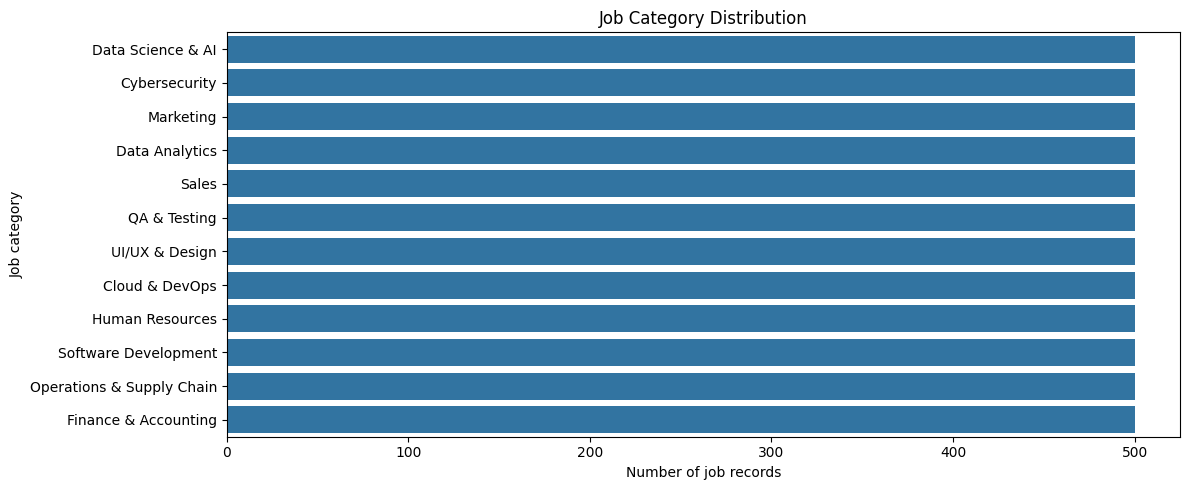

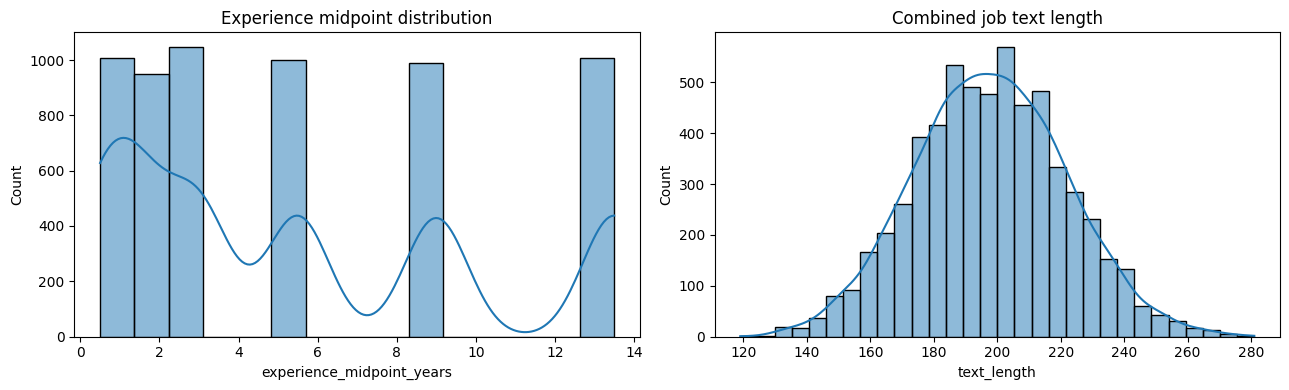

In [62]:
print("Dataset shape:", df.shape)
print("Number of categories:", df["job_category"].nunique())
display(df["job_category"].value_counts().rename("job_count").to_frame())

plt.figure(figsize=(12,5))
order = df["job_category"].value_counts().index
sns.countplot(data=df, y="job_category", order=order)
plt.title("Job Category Distribution")
plt.xlabel("Number of job records")
plt.ylabel("Job category")
plt.tight_layout()
plt.show()

df["text_length"] = (
    df["job_title"].fillna("").astype(str) + " " +
    df["job_description"].fillna("").astype(str) + " " +
    df["skills"].fillna("").astype(str)
).str.len()

fig, ax = plt.subplots(1,2,figsize=(13,4))
sns.histplot(df["experience_midpoint_years"], bins=15, kde=True, ax=ax[0])
ax[0].set_title("Experience midpoint distribution")
sns.histplot(df["text_length"], bins=30, kde=True, ax=ax[1])
ax[1].set_title("Combined job text length")
plt.tight_layout()
plt.show()

## 4. Prepare Features and Target
Combine title, description and skills into one text field. Location and experience are additional features. `job_id` is never used as a feature.

In [63]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

work = df.copy()
work["combined_text"] = (
    work["job_title"].fillna("").astype(str) + " " +
    work["job_description"].fillna("").astype(str) + " " +
    work["skills"].fillna("").astype(str)
)
FEATURES = ["combined_text", "location", "experience_midpoint_years"]
TARGET = "job_category"
X = work[FEATURES]
y = work[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train category distribution:\n", y_train.value_counts())

Train rows: 4800 | Test rows: 1200
Train category distribution:
 job_category
Sales                        400
Human Resources              400
Cloud & DevOps               400
Finance & Accounting         400
Software Development         400
UI/UX & Design               400
QA & Testing                 400
Operations & Supply Chain    400
Cybersecurity                400
Marketing                    400
Data Analytics               400
Data Science & AI            400
Name: count, dtype: int64


## 5. Build Preprocessing Pipeline
TF-IDF converts job text into numeric features. One-hot encoding handles location. The numeric experience feature is scaled. Preprocessing is fitted only on training data through each Pipeline.

In [64]:
from sklearn.preprocessing import MinMaxScaler

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("text", TfidfVectorizer(max_features=8000, ngram_range=(1,2),
                                     stop_words="english", min_df=2), "combined_text"),
            ("location", OneHotEncoder(handle_unknown="ignore"), ["location"]),
            ("experience", StandardScaler(), ["experience_midpoint_years"])
        ],
        remainder="drop"
    )

# MultinomialNB requires non-negative inputs. TF-IDF and one-hot are non-negative;
# the experience feature is therefore MinMax-scaled for this model.
def make_nb_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("text", TfidfVectorizer(max_features=8000, ngram_range=(1,2),
                                     stop_words="english", min_df=2), "combined_text"),
            ("location", OneHotEncoder(handle_unknown="ignore"), ["location"]),
            ("experience", MinMaxScaler(), ["experience_midpoint_years"])
        ],
        remainder="drop"
    )

## 6. Train Syllabus Classification Algorithms
Algorithms: Logistic Regression, KNN, Decision Tree, Random Forest, Naive Bayes and SVM (LinearSVC).

In [65]:
models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "K-Nearest Neighbours": Pipeline([("prep", make_preprocessor()),
        ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))]),
    "Decision Tree": Pipeline([("prep", make_preprocessor()),
        ("model", DecisionTreeClassifier(max_depth=30, min_samples_leaf=2, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", make_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                         class_weight="balanced_subsample",
                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    "Naive Bayes": Pipeline([("prep", make_nb_preprocessor()),
        ("model", MultinomialNB(alpha=0.5))]),
    "SVM (LinearSVC)": Pipeline([("prep", make_preprocessor()),
        ("model", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))])
}

results = []
fitted_models = {}
for name, pipe in models.items():
    print("Training:", name)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

classification_results = pd.DataFrame(results).sort_values(
    ["F1_macro", "Accuracy"], ascending=False
).reset_index(drop=True)
display(classification_results.round(4))
classification_results.to_csv(os.path.join(RESULTS_DIR, "classification_model_comparison.csv"), index=False)

Training: Logistic Regression
Training: K-Nearest Neighbours
Training: Decision Tree
Training: Random Forest
Training: Naive Bayes
Training: SVM (LinearSVC)


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,SVM (LinearSVC),0.9517,0.9518,0.9517,0.9516
1,Logistic Regression,0.9250,0.9253,0.9250,0.9248
2,Naive Bayes,0.9042,0.9061,0.9042,0.9042
3,Random Forest,0.8442,0.8466,0.8442,0.8432
4,Decision Tree,0.6033,0.6974,0.6033,0.6304
5,K-Nearest Neighbours,0.3658,0.3820,0.3658,0.3703


## 7. Compare Model Performance

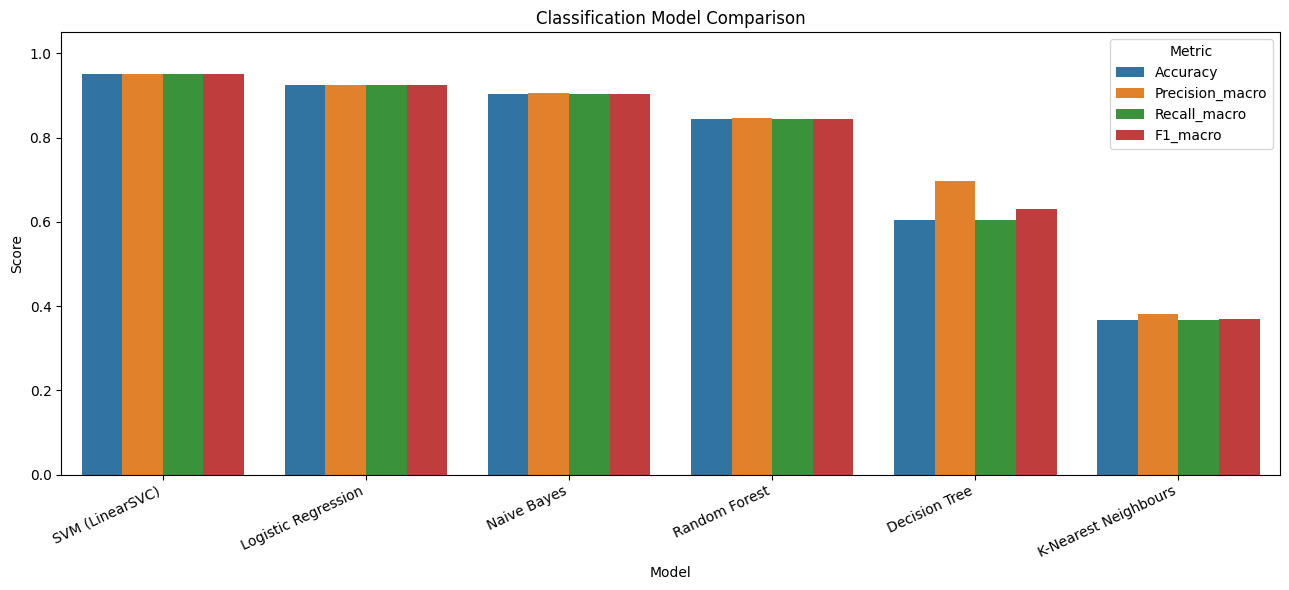

In [66]:
metrics_to_plot = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]
plot_df = classification_results.melt(id_vars="Model", value_vars=metrics_to_plot,
                                      var_name="Metric", value_name="Score")
plt.figure(figsize=(13,6))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0,1.05)
plt.xticks(rotation=25, ha="right")
plt.title("Classification Model Comparison")
plt.tight_layout()
plt.show()

## 8. Select Best Model and Explain Selection
Selection uses macro F1 first, then accuracy. Macro F1 gives every category equal importance. The held-out test set is used only for final comparison; no metric is hardcoded.

Selected model: SVM (LinearSVC)

Reason: it has the highest macro F1 on the held-out test set (accuracy breaks ties).

Classification report:

                           precision    recall  f1-score   support

           Cloud & DevOps       0.98      0.93      0.95       100
            Cybersecurity       0.95      0.97      0.96       100
           Data Analytics       0.89      0.91      0.90       100
        Data Science & AI       0.93      0.90      0.91       100
     Finance & Accounting       0.98      0.94      0.96       100
          Human Resources       0.98      0.99      0.99       100
                Marketing       0.96      1.00      0.98       100
Operations & Supply Chain       0.97      0.96      0.96       100
             QA & Testing       0.94      0.94      0.94       100
                    Sales       0.95      0.96      0.96       100
     Software Development       0.93      0.93      0.93       100
           UI/UX & Design       0.96      0.99      

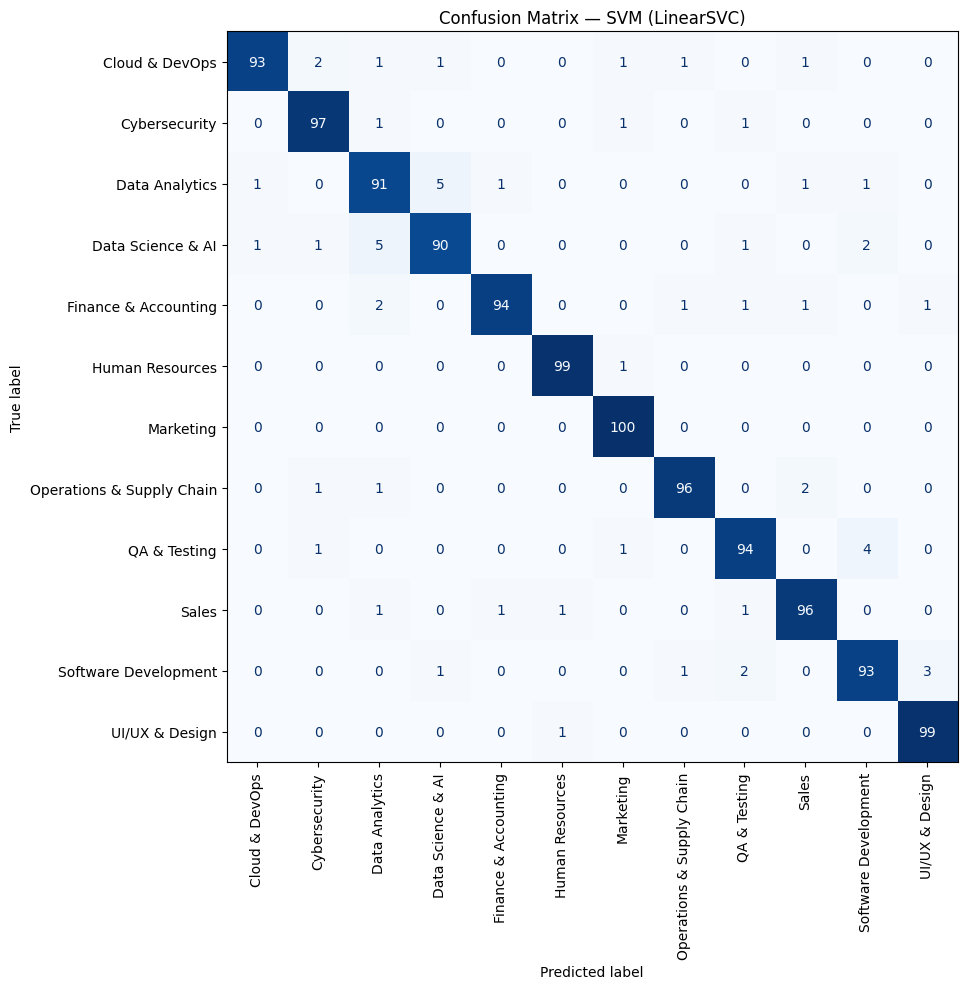

Best model metrics:


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,SVM (LinearSVC),0.9517,0.9518,0.9517,0.9516


In [67]:
best_name = classification_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("\nReason: it has the highest macro F1 on the held-out test set (accuracy breaks ties).")
print("\nClassification report:\n")
print(classification_report(y_test, best_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)
fig, ax = plt.subplots(figsize=(12,10))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

print("Best model metrics:")
display(classification_results.iloc[[0]].round(4))

## 9. Cross-Validation Check
Cross-validation is performed on the training split only. It gives an additional stability estimate; the held-out test score remains the final test result.

In [68]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print("5-fold training CV macro-F1 scores:", np.round(cv_scores,4))
print("Mean CV macro-F1:", round(cv_scores.mean(),4))
print("Std CV macro-F1:", round(cv_scores.std(),4))

5-fold training CV macro-F1 scores: [0.9573 0.9466 0.9427 0.9519 0.9417]
Mean CV macro-F1: 0.948
Std CV macro-F1: 0.0059


## 10. Save Model, Processed Data and Results

In [69]:
joblib.dump(best_model, os.path.join(MODEL_DIR, "job_classifier_best.joblib"))
joblib.dump(best_name, os.path.join(MODEL_DIR, "job_classifier_best_name.joblib"))
work.to_csv(os.path.join(PROCESSED_DIR, "classification_processed.csv"), index=False)
classification_results.to_csv(os.path.join(RESULTS_DIR, "classification_model_comparison.csv"), index=False)

summary = {
    "agent": "Job Classification",
    "selected_model": best_name,
    "selection_metric": "macro F1, accuracy as tie-breaker",
    "test_metrics": classification_results.iloc[0].to_dict(),
    "cross_validation_macro_f1_mean": float(cv_scores.mean()),
    "cross_validation_macro_f1_std": float(cv_scores.std()),
    "dataset_rows": int(len(work)),
    "dataset_type": "synthetic academic dataset"
}
with open(os.path.join(RESULTS_DIR, "classification_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)

print("Saved classifier and results to:", BASE_DIR)

Saved classifier and results to: /content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind


## 11. Test a New Job Profile

In [36]:
sample_job = pd.DataFrame([{
    "combined_text": "Data Scientist builds machine learning models using Python, SQL, statistics and deep learning.",
    "location": "Bengaluru",
    "experience_midpoint_years": 3.0
}])
sample_prediction = best_model.predict(sample_job)[0]
print("Predicted job category:", sample_prediction)
if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample_job)[0]
    print("Model confidence for predicted class:", round(float(probabilities.max()),4))
else:
    print("This selected model does not provide calibrated class probabilities.")

Predicted job category: Data Science & AI
This selected model does not provide calibrated class probabilities.
